File `cleaned_test.csv` có cấu trúc giống `cleaned.csv` nhưng **không có cột `SalePrice`**, nên chỉ dự báo được, không đo được sai số. Quy trình:

1. Đọc file với **đúng cách đọc như `cleaned.csv`** (`keep_default_na=False, na_values=["", "NA"]`) và kiểm tra cột/giá trị lạ.
2. Dùng `predict_price()` ở trên: hàm nạp bản mô hình đã lưu (huấn luyện trên toàn bộ dữ liệu), chạy `engineer()` rồi dự báo.
3. **Không loại dòng nào** (khác bước 3 lúc huấn luyện): việc loại outlier chỉ dành cho dữ liệu học; ở đây mọi căn đều cần có dự báo. Căn nào có `GrLivArea` > 4000 sẽ được cảnh báo để xem xét thủ công.
4. Lưu kết quả ra `reports/outputs/predictions_test.csv` gồm `Id`, giá dự báo và khoảng 90%.

In [40]:
import os, warnings, time, joblib
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (train_test_split, KFold, cross_validate,
                                     cross_val_predict, GridSearchCV, RandomizedSearchCV)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, VotingRegressor)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             mean_absolute_percentage_error)

OUT_DIR = "../reports/outputs/"      # thư mục lưu mô hình & bảng kết quả
FIG_OUT = "../reports/figures/"      # thư mục lưu hình
DATA_PATH = "../data/processed/cleaned.csv"
TEST_PATH = "../data/processed/cleaned_test.csv"

out_mask = (raw["GrLivArea"] > 4000) & (raw["SalePrice"] < 300000)
df = raw.loc[~out_mask].reset_index(drop=True)
usd = plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k")   # định dạng trục giá (nghìn USD)

QUAL_COLS = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
             "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]
QUAL = {"NoBasement": 0, "NoGarage": 0, "NoFireplace": 0, "NoPool": 0,
        "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
BSMT_FIN = {"NoBasement": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6}
ORD_MAPS = {
    "BsmtExposure": {"NoBasement": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFinType1": BSMT_FIN,
    "BsmtFinType2": BSMT_FIN,
    "GarageFinish": {"NoGarage": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "Functional":   {"Sal": 1, "Sev": 2, "Maj2": 3, "Maj1": 4, "Mod": 5, "Min2": 6, "Min1": 7, "Typ": 8},
    "LotShape":     {"IR3": 1, "IR2": 2, "IR1": 3, "Reg": 4},
    "LandSlope":    {"Sev": 1, "Mod": 2, "Gtl": 3},
    "PavedDrive":   {"N": 0, "P": 1, "Y": 2},
    "CentralAir":   {"N": 0, "Y": 1},
}

df_fe = engineer(df)
TARGET = "SalePrice"
X = df_fe.drop(columns=[TARGET])

def engineer(d):
    d = d.copy()

    # 1) mã hóa thứ bậc
    for c in QUAL_COLS:
        d[c] = d[c].map(QUAL)
    for c, m in ORD_MAPS.items():
        d[c] = d[c].map(m)

    # 2) biến tổng hợp
    d["TotalSF"]       = d["TotalBsmtSF"] + d["1stFlrSF"] + d["2ndFlrSF"]
    d["TotalBath"]     = d["FullBath"] + 0.5 * d["HalfBath"] + d["BsmtFullBath"] + 0.5 * d["BsmtHalfBath"]
    d["TotalPorchSF"]  = d["OpenPorchSF"] + d["EnclosedPorch"] + d["3SsnPorch"] + d["ScreenPorch"]
    d["HouseAge"]      = (d["YrSold"] - d["YearBuilt"]).clip(lower=0)
    d["RemodAge"]      = (d["YrSold"] - d["YearRemodAdd"]).clip(lower=0)
    d["IsRemodeled"]   = (d["YearRemodAdd"] != d["YearBuilt"]).astype(int)
    d["IsNewHouse"]    = (d["YrSold"] == d["YearBuilt"]).astype(int)
    d["HasBsmt"]       = (d["TotalBsmtSF"] > 0).astype(int)
    d["Has2ndFlr"]     = (d["2ndFlrSF"] > 0).astype(int)
    d["HasGarage"]     = (d["GarageArea"] > 0).astype(int)
    d["HasFireplace"]  = (d["Fireplaces"] > 0).astype(int)
    d["HasPool"]       = (d["PoolArea"] > 0).astype(int)

    # 3) tương tác diện tích x chất lượng
    d["Qual_x_GrLivArea"] = d["OverallQual"] * d["GrLivArea"]
    d["Qual_x_TotalSF"]   = d["OverallQual"] * d["TotalSF"]

    # 4) biến mã/tháng -> phân loại
    d["MSSubClass"] = d["MSSubClass"].astype(str)
    d["MoSold"]     = d["MoSold"].astype(str)

    # 5) bỏ cột không dùng
    return d.drop(columns=["Id", "GarageYrBlt", "Utilities"])

def predict_price(raw_df, bundle_path=os.path.join(OUT_DIR, "house_price_model.joblib")):
    # raw_df: DataFrame có cùng cột như cleaned.csv (đọc với keep_default_na=False, na_values=['', 'NA']).
    # Trả về giá dự báo và khoảng 90%.
    b = joblib.load(bundle_path)
    feats = engineer(raw_df.assign(SalePrice=np.nan))[b["feature_columns"]]
    p = b["model"].predict(feats)
    lo, hi = b["prediction_interval_log"]
    return pd.DataFrame({"Giá dự báo": np.expm1(p).round(-2),
                         "Thấp (90%)": np.expm1(p + lo).round(-2),
                         "Cao (90%)":  np.expm1(p + hi).round(-2)}, index=raw_df.index)

def savefig(name):
    plt.savefig(os.path.join(FIG_OUT, name), dpi=130, bbox_inches="tight")

In [41]:
PRED_PATH = os.path.join(OUT_DIR, "predictions_test.csv")

raw = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=["", "NA"])
test_raw = pd.read_csv(TEST_PATH, keep_default_na=False, na_values=["", "NA"])
print("Nguồn dữ liệu:", TEST_PATH)
print("Kích thước:", test_raw.shape)

# --- 1) Kiểm tra cấu trúc: phải có đủ các cột của cleaned.csv (trừ SalePrice) ---
expected_cols = [c for c in raw.columns if c != "SalePrice"]
missing_cols = [c for c in expected_cols if c not in test_raw.columns]
extra_cols = [c for c in test_raw.columns if c not in raw.columns]
assert not missing_cols, f"cleaned_test.csv thiếu các cột: {missing_cols}"
if extra_cols:
    print("Cột thừa (sẽ bị bỏ qua):", extra_cols)
if "SalePrice" in test_raw.columns:
    print("Cảnh báo: file test đã có cột SalePrice -> sẽ bị bỏ qua, không dùng khi dự báo.")

# --- 2) Hạng mục thứ bậc chưa từng thấy (sẽ thành NaN sau khi mã hóa, rồi bị điền median) ---
ordinal_maps = {**{c: QUAL for c in QUAL_COLS}, **ORD_MAPS}
unseen = {c: sorted(set(test_raw[c].dropna().unique()) - set(m))
          for c, m in ordinal_maps.items()}
unseen = {c: v for c, v in unseen.items() if v}
print("\nGiá trị thứ bậc lạ:", unseen if unseen else "không có")

# --- 3) Các cột còn thiếu giá trị sau feature engineering ---
feats_test = engineer(test_raw.assign(SalePrice=np.nan))[X.columns.tolist()]
nan_test = feats_test.isna().sum()
nan_test = nan_test[nan_test > 0]
print("\nCột còn thiếu giá trị (sẽ được điền theo median/'Missing' của mô hình):")
print(nan_test.to_string() if len(nan_test) else "không có")

# --- 4) Cảnh báo căn giống outlier đã loại khi huấn luyện ---
big = test_raw["GrLivArea"] > 4000
print(f"\nSố căn có GrLivArea > 4000 (ngoài vùng dữ liệu huấn luyện, dự báo kém tin cậy): {big.sum()}")

Nguồn dữ liệu: ../data/processed/cleaned_test.csv
Kích thước: (1459, 80)

Giá trị thứ bậc lạ: không có

Cột còn thiếu giá trị (sẽ được điền theo median/'Missing' của mô hình):
MSZoning        4
Exterior1st     1
Exterior2nd     1
MasVnrType     16
KitchenQual     1
Functional      2
GarageCars      1
GarageArea      1
SaleType        1

Số căn có GrLivArea > 4000 (ngoài vùng dữ liệu huấn luyện, dự báo kém tin cậy): 1


In [42]:
# --- Dự báo (hàm predict_price tự nạp mô hình đã lưu và chạy engineer()) ---
pred_df = predict_price(test_raw)

submission = pd.DataFrame({
    "Id": test_raw["Id"].values if "Id" in test_raw.columns else np.arange(len(test_raw)),
    "SalePrice":      pred_df["Giá dự báo"].values,
    "SalePrice_Low90":  pred_df["Thấp (90%)"].values,
    "SalePrice_High90": pred_df["Cao (90%)"].values,
})
assert len(submission) == len(test_raw) and submission["SalePrice"].notna().all()

submission.to_csv(PRED_PATH, index=False)
print(f"Đã lưu {len(submission)} dự báo -> {PRED_PATH}")
submission.head(10)

Đã lưu 1459 dự báo -> ../reports/outputs/predictions_test.csv


,Id,SalePrice,SalePrice_Low90,SalePrice_High90
0,1461,120400.0,101100.0,140100.0
1,1462,160300.0,134600.0,186400.0
2,1463,178800.0,150100.0,208000.0
3,1464,193400.0,162300.0,224900.0
4,1465,193200.0,162200.0,224700.0
5,1466,170500.0,143100.0,198300.0
6,1467,176400.0,148100.0,205200.0
7,1468,163800.0,137500.0,190500.0
8,1469,190700.0,160100.0,221800.0
9,1470,120500.0,101100.0,140100.0


,Train (thực tế),Test (dự báo)
count,1458.000000,1459.000000
mean,180932.919067,178325.976696
std,79495.055285,77705.698636
min,34900.000000,41800.000000
25%,129925.000000,126800.000000
50%,163000.000000,156600.000000
75%,214000.000000,210650.000000
max,755000.000000,806200.000000


Số dự báo nằm ngoài khoảng giá đã thấy khi huấn luyện [34,900 – 755,000]: 1


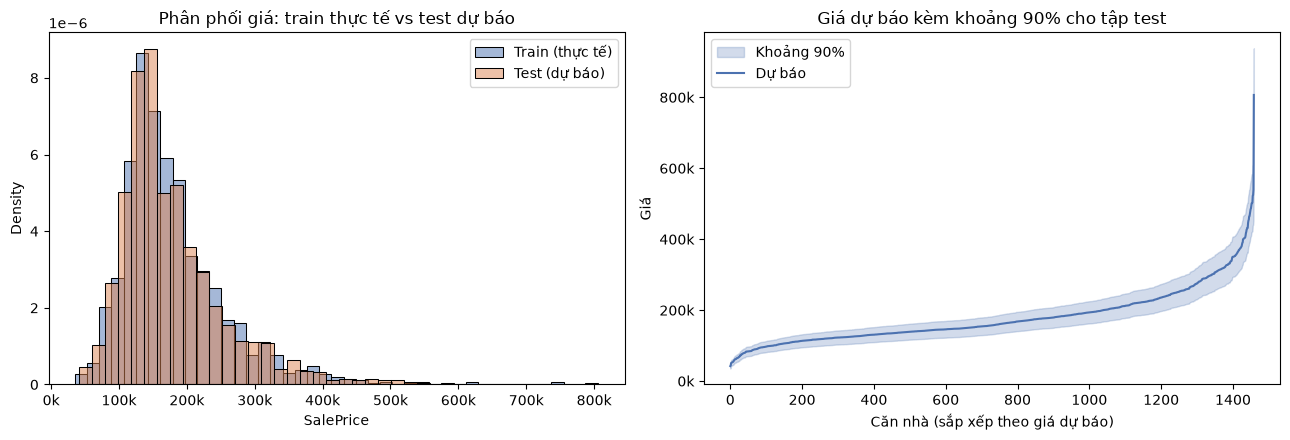

In [43]:
# --- Kiểm tra hợp lý: phân phối giá dự báo so với giá thực tế của dữ liệu huấn luyện ---
train_price = df["SalePrice"]
summary = pd.DataFrame({"Train (thực tế)": train_price.describe(),
                        "Test (dự báo)":   submission["SalePrice"].describe()})
display(summary)

out_of_range = ((submission["SalePrice"] < train_price.min()) |
                (submission["SalePrice"] > train_price.max())).sum()
print(f"Số dự báo nằm ngoài khoảng giá đã thấy khi huấn luyện "
      f"[{train_price.min():,.0f} – {train_price.max():,.0f}]: {out_of_range}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(train_price, stat="density", bins=40, color="#4C72B0", alpha=0.5,
             label="Train (thực tế)", ax=axes[0])
sns.histplot(submission["SalePrice"], stat="density", bins=40, color="#DD8452", alpha=0.5,
             label="Test (dự báo)", ax=axes[0])
axes[0].xaxis.set_major_formatter(usd); axes[0].legend()
axes[0].set_title("Phân phối giá: train thực tế vs test dự báo")

order = submission["SalePrice"].sort_values().index
axes[1].fill_between(range(len(order)), submission.loc[order, "SalePrice_Low90"],
                     submission.loc[order, "SalePrice_High90"], alpha=0.25, color="#4C72B0",
                     label="Khoảng 90%")
axes[1].plot(range(len(order)), submission.loc[order, "SalePrice"].values, color="#4C72B0", lw=1.5,
             label="Dự báo")
axes[1].yaxis.set_major_formatter(usd); axes[1].legend()
axes[1].set_xlabel("Căn nhà (sắp xếp theo giá dự báo)"); axes[1].set_ylabel("Giá")
axes[1].set_title("Giá dự báo kèm khoảng 90% cho tập test")
plt.tight_layout(); savefig("m09_test_predictions.png"); plt.show()